In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('Xor_Dataset.csv').values

X = data[:,:2]
y = data[:,2:]

In [ ]:
def sigmoid(z):
    return 1.0/(1.0+np.exp(-z))

def sigmoid_derivative(a):
    return a*(1.0-a)

def mse(y_pred,y_true):
    return np.mean((y_pred - y_true) ** 2)

In [ ]:
def train_nn(X,y,learning_rate=0.5,epochs=10000,seed=4):
    np.random.seed(seed)
    
    W1 = np.random.uniform(-1,1,(2,2))
    b1 = np.zeros((1,2))
    W2 = np.random.uniform(-1,1,(2,1))
    b2 = np.zeros((1,1))
    
    loss_history = []

    for epoch in range(epochs + 1):
        z1 = np.dot(X,W1) + b1
        a1 = sigmoid(z1)
        z2 = np.dot(a1,W2) + b2
        a2 = sigmoid(z2)
        loss = mse(a2,y)
        loss_history.append(loss)
        
        dL_da2 = 2 * (a2 - y)/len(X)
        dL_dz2 = dL_da2 * sigmoid_derivative(a2)
        dL_dW2 = np.dot(a1.T,dL_dz2)
        dL_db2 = np.sum(dL_dz2,axis=0,keepdims=True)
        
        dL_da1 = np.dot(dL_dz2,W2.T)
        dL_dz1 = dL_da1 * sigmoid_derivative(a1)
        dL_dW1 = np.dot(X.T,dL_dz1)
        dL_db1 = np.sum(dL_dz1,axis=0,keepdims=True) 
        

        W1 -= learning_rate * dL_dW1
        b1 -= learning_rate * dL_db1
        W2 -= learning_rate * dL_dW2
        b2 -= learning_rate * dL_db2
        
        if epoch % 2000 == 0:
            print(f"Epoch {epoch:5d} and MSE Loss: {loss:.6f}")
            
    return a2,loss_history,(W1,b1,W2,b2)


a2_plot,loss_plot,parameters = train_nn(X,y,learning_rate=0.5,epochs=10000)
a2_plot1,loss_plot1,parameters1 = train_nn(X,y,learning_rate=0.05,epochs=10000)

Epoch     0 | MSE Loss: 0.248650
Epoch  2000 | MSE Loss: 0.009787
Epoch  4000 | MSE Loss: 0.002378
Epoch  6000 | MSE Loss: 0.001294
Epoch  8000 | MSE Loss: 0.000878
Epoch 10000 | MSE Loss: 0.000661
Epoch     0 | MSE Loss: 0.248650
Epoch  2000 | MSE Loss: 0.244390
Epoch  4000 | MSE Loss: 0.232502
Epoch  6000 | MSE Loss: 0.207942
Epoch  8000 | MSE Loss: 0.177113
Epoch 10000 | MSE Loss: 0.131677


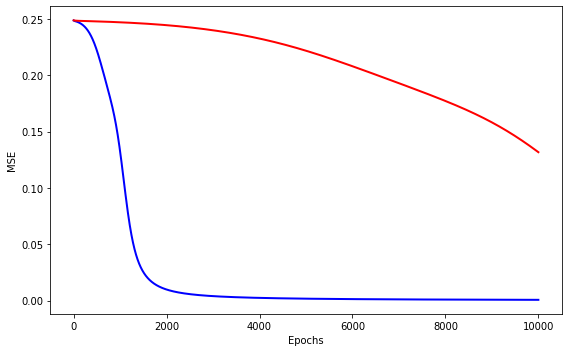

In [39]:
plt.figure(figsize=(8,5))
plt.plot(loss_plot, color="blue",linewidth=2)
plt.plot(loss_plot1,color="red",linewidth=2)
plt.xlabel("Epochs",fontsize=10)
plt.ylabel("MSE",fontsize=10)
plt.tight_layout()
plt.show()

In [35]:
print(f"Input (x1,x2): Target (y): Predicted Prob: Class")
for i in range(len(X)):
    x_str = f"[{int(X[i][0])},{int(X[i][1])}]"
    target = int(y[i][0])
    prob = a2_plot[i][0]
    binary_class = int(prob >= 0.5)
    print(f"{x_str:<15} {target:<10} {prob:<16.4f} {binary_class}")

Input (x1,x2): Target (y): Predicted Prob: Class
[0,0]           0          0.0285           0
[0,1]           1          0.9756           1
[1,1]           0          0.0254           0
[1,1]           0          0.0254           0
[0,0]           0          0.0285           0
[1,0]           1          0.9757           1
[1,1]           0          0.0254           0
[1,1]           0          0.0254           0
[0,1]           1          0.9756           1
[1,0]           1          0.9757           1
[0,0]           0          0.0285           0
[1,1]           0          0.0254           0
[1,0]           1          0.9757           1
[0,1]           1          0.9756           1
[1,0]           1          0.9757           1
[1,1]           0          0.0254           0
[0,1]           1          0.9756           1
[0,0]           0          0.0285           0
[1,0]           1          0.9757           1
[0,0]           0          0.0285           0
[1,1]           0          0.02

In [44]:
def train_nn_regu(X,y,learning_rate=0.5,lambda_reg=0.5,epochs=10000,seed=4):
    
    np.random.seed(seed)
    W1 = np.random.uniform(-1,1,(2,2))
    b1 = np.zeros((1,2))
    W2 = np.random.uniform(-1,1,(2,1))
    b2 = np.zeros((1,1))
    
    loss_history = []

    for epoch in range(epochs + 1):
        z1 = np.dot(X,W1) + b1
        a1 = sigmoid(z1)
        z2 = np.dot(a1,W2) + b2
        a2 = sigmoid(z2)

        l2_penalty = (lambda_reg / (2 * len(X))) * (np.sum(W1**2) + np.sum(W2**2))
        loss = mse(a2,y) + l2_penalty
        loss_history.append(loss)
        
        dL_da2 = 2 * (a2 - y) / len(X)
        dL_dz2 = dL_da2 * sigmoid_derivative(a2)
        dL_dW2 = np.dot(a1.T,dL_dz2) + (lambda_reg/len(X))*W2
        dL_db2 = np.sum(dL_dz2,axis=0,keepdims=True)
        
        dL_da1 = np.dot(dL_dz2,W2.T)
        dL_dz1 = dL_da1 * sigmoid_derivative(a1)
        dL_dW1 = np.dot(X.T,dL_dz1) + (lambda_reg/len(X))*W1
        dL_db1 = np.sum(dL_dz1,axis=0,keepdims=True)
        
        W1 -= learning_rate * dL_dW1
        b1 -= learning_rate * dL_db1
        W2 -= learning_rate * dL_dW2
        b2 -= learning_rate * dL_db2
        
        if epoch % 2000 == 0:
            print(f"Epoch {epoch:5d} and Total Loss: {loss:.6f}")
            
    return a2,loss_history,(W1,b1,W2,b2)

a2_plot_reg,loss_plot_reg,parameters_reg = train_nn(X,y,learning_rate=0.5,epochs=10000)
a2_plot1_reg,loss_plot1_reg,parameters1_reg = train_nn(X,y,learning_rate=0.05,epochs=10000)

Epoch     0 | MSE Loss: 0.248650
Epoch  2000 | MSE Loss: 0.009787
Epoch  4000 | MSE Loss: 0.002378
Epoch  6000 | MSE Loss: 0.001294
Epoch  8000 | MSE Loss: 0.000878
Epoch 10000 | MSE Loss: 0.000661
Epoch     0 | MSE Loss: 0.248650
Epoch  2000 | MSE Loss: 0.244390
Epoch  4000 | MSE Loss: 0.232502
Epoch  6000 | MSE Loss: 0.207942
Epoch  8000 | MSE Loss: 0.177113
Epoch 10000 | MSE Loss: 0.131677


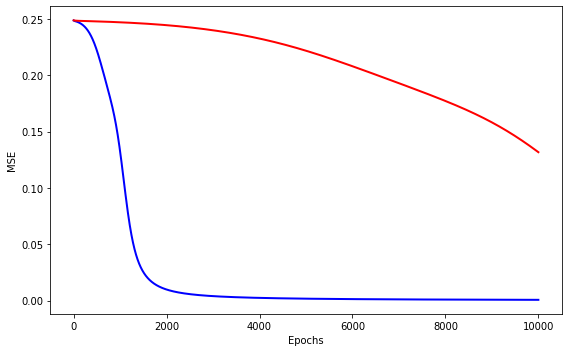

In [43]:
plt.figure(figsize=(8,5))
plt.plot(loss_plot_reg, color="blue",linewidth=2)
plt.plot(loss_plot1_reg,color="red",linewidth=2)
plt.xlabel("Epochs",fontsize=10)
plt.ylabel("MSE",fontsize=10)
plt.tight_layout()
plt.show()